# Week 1: Python for Financial Data & Market Microstructure

This notebook is a guided walkthrough of the Week 1 plan in the roadmap. It focuses on the concepts, the core ideas, and the code needed to understand the key stylized facts in financial time series. We are not doing the final lab deliverable here; instead, this is a study guide with proofs in code.

## Learning goals

By the end of this notebook, you should be able to:

- explain the difference between tick-level data and OHLCV data;
- compute arithmetic and log returns correctly;
- understand why market data is not i.i.d. Gaussian noise;
- see and prove the main stylized facts with code;
- interpret volatility clustering, heavy tails, and autocorrelation of absolute returns.

## Week 1 plan from the roadmap

- Order book mechanics: bids, asks, market depth, bid-ask spread, and slippage.
- Tick-level versus OHLCV data.
- Stylized facts of financial time series: fat tails, leptokurtosis, volatility clustering, and autocorrelation of absolute returns.
- Vectorized data processing with NumPy and pandas.
- Pulling historical data using market APIs such as yfinance.
- Computing log returns versus arithmetic returns and understanding compounding.

## 1. Why this matters in practice

Financial markets are noisy, clustered, and nonlinear. If you look at the return series of a liquid asset, the distribution is usually not well described by a simple bell curve. The classic empirical facts are not quirks; they shape how we build models, test hypotheses, estimate risk, and design trading strategies.

A good first question is: what does the data actually look like?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

sns.set_theme(style='whitegrid')

print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('yfinance:', yf.__version__)

NumPy: 2.5.3
Pandas: 3.0.6
yfinance: 1.7.0


## 2. Pulling market data

We will use `yfinance` to obtain daily price data for SPY. In real research, always record the source, date range, and assumptions. We will also include a fallback so the notebook keeps working even if the remote data service is unavailable.

In [2]:
# Download daily adjusted close data for SPY.
# A real workflow should always record the source, date range, and assumptions.
prices = yf.download(
    "SPY",
    start="2018-01-01",
    end="2025-12-31",
    auto_adjust=False,
    progress=False,
)
if "Adj Close" in prices.columns:
    prices = prices["Adj Close"]

# Remove index    
prices = prices.iloc[:, 0]

print("Downloaded data shape:", prices.shape)
prices = prices.copy()
prices.head()

Downloaded data shape: (2010,)


Date
2018-01-02    235.369827
2018-01-03    236.858627
2018-01-04    237.856857
2018-01-05    239.441879
2018-01-08    239.879852
Name: SPY, dtype: float64

## 3. The data work flow: prices, returns, and compounding

The raw series is price level data. For analysis, we typically transform it into returns. That allows us to compare across assets and to study the distribution of changes rather than the level of the price.

We will compute:

- arithmetic return: $r_t = P_t / P_{t-1} - 1$
- log return: $r_t = \log(P_t / P_{t-1})$

These are close for small daily moves, but they are not identical, and log returns are convenient for compounding and time aggregation.

In [3]:
# Clean data and create return series.
prices = prices.dropna()
clean = pd.DataFrame({'SPY': prices})
clean['SPY_arith_return'] = clean['SPY'].pct_change()
clean['SPY_log_return'] = np.log(clean['SPY'] / clean['SPY'].shift(1))

clean.head()

,SPY,SPY_arith_return,SPY_log_return
Date,,,
2018-01-02,235.369827,NaN,NaN
2018-01-03,236.858627,0.006325,0.006305
2018-01-04,237.856857,0.004214,0.004206
2018-01-05,239.441879,0.006664,0.006642
2018-01-08,239.879852,0.001829,0.001827


In [4]:
# Compare arithmetic versus log returns on a single asset.
comparison = clean[['SPY', 'SPY_arith_return', 'SPY_log_return']].dropna().head(10)
comparison

,SPY,SPY_arith_return,SPY_log_return
Date,,,
2018-01-03,236.858627,0.006325,0.006305
2018-01-04,237.856857,0.004214,0.004206
2018-01-05,239.441879,0.006664,0.006642
2018-01-08,239.879852,0.001829,0.001827
2018-01-09,240.422791,0.002263,0.002261
2018-01-10,240.054947,-0.001530,-0.001531
2018-01-11,241.806442,0.007296,0.007270
2018-01-12,243.382797,0.006519,0.006498
2018-01-16,242.550751,-0.003419,-0.003425


In [5]:
# A quick check of the relationship between arithmetic and log returns.
spy = clean['SPY_arith_return'].dropna()
log_spy = clean['SPY_log_return'].dropna()

approx = pd.DataFrame({
    'arith': spy.head(5).values,
    'log': log_spy.head(5).values,
    'difference': (spy.head(5) - log_spy.head(5)).values
})
approx

,arith,log,difference
0,0.006325,0.006305,0.000020
1,0.004214,0.004206,0.000009
2,0.006664,0.006642,0.000022
3,0.001829,0.001827,0.000002
4,0.002263,0.002261,0.000003


## 4. Tick-level data versus OHLCV data

This is a key market-microstructure distinction.

- Tick-level data is every trade or quote update: extremely detailed, high-frequency, and noisy.
- OHLCV data aggregates trades into open-high-low-close-volume bars over a fixed interval (1 minute, 1 hour, 1 day).

The choice matters because the aggregation method can hide or distort microstructure features such as bid-ask bounce, spread dynamics, and liquidity bursts.

In a simple world, a trade can happen at a price that is only a tiny move from the prior trade. In a real order book, price changes are shaped by the queue of buy and sell orders, not just by an underlying latent process.

In [6]:
# A simple illustration of OHLCV-style aggregation.
# We create a small synthetic tick series and then convert it to 5-tick bars.
np.random.seed(7)
ticks = pd.Series(np.cumsum(np.random.normal(0, 1, 25)), index=pd.date_range('2025-01-01', periods=25, freq='min'))

bars = pd.DataFrame({
    'open': ticks.groupby(np.arange(len(ticks)) // 5).first(),
    'high': ticks.groupby(np.arange(len(ticks)) // 5).max(),
    'low': ticks.groupby(np.arange(len(ticks)) // 5).min(),
    'close': ticks.groupby(np.arange(len(ticks)) // 5).last(),
    'volume': 100 + np.random.randint(0, 50, size=(len(ticks) + 4) // 5)
})

bars.head()

,open,high,low,close,volume
0,1.690526,1.690526,0.876002,0.876002,128
1,0.878067,0.878067,-0.877547,0.740609,107
2,0.115180,0.448931,-0.056368,-0.055174,123
3,-1.508416,-0.555494,-2.082019,-2.082019,110
4,-0.431319,1.364948,-0.664124,1.319562,141


## 5. Stylized fact 1: Financial returns are heavy-tailed and leptokurtic

One of the strongest empirical facts is that returns have fatter tails than a normal distribution. This means extreme moves are more common than a Gaussian model implies.

We can check this using the sample excess kurtosis:

- if the normal distribution is the benchmark, then excess kurtosis is 0;
- in equity returns, excess kurtosis is often positive and substantial.

A simple proof is to compare the return distribution to a normal curve.

SPY mean return: 0.000529
SPY volatility: 0.012288
SPY skewness: -0.574982
SPY kurtosis: 13.497990
SPY excess kurtosis: 13.497990


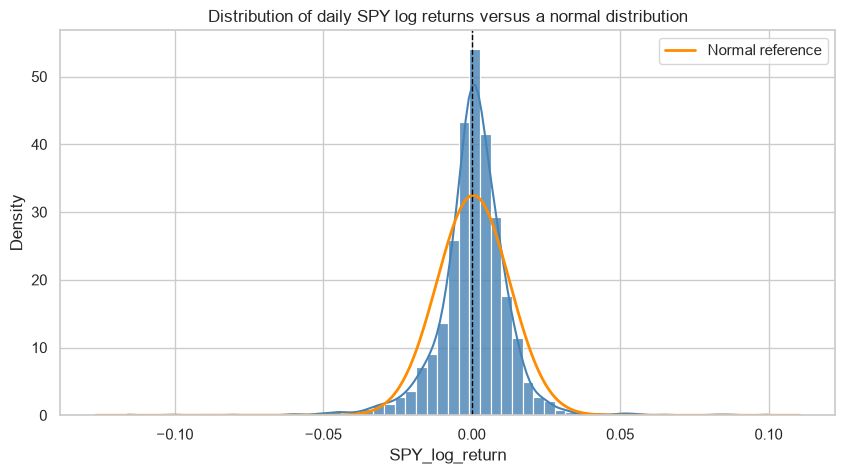

In [7]:
# Use one asset and compute the distributional features.
spy_returns = clean['SPY_log_return'].dropna()

mean = spy_returns.mean()
std = spy_returns.std(ddof=1)
skew = spy_returns.skew()
kurtosis = spy_returns.kurtosis()
excess_kurtosis = kurtosis

print(f'SPY mean return: {mean:.6f}')
print(f'SPY volatility: {std:.6f}')
print(f'SPY skewness: {skew:.6f}')
print(f'SPY kurtosis: {kurtosis:.6f}')
print(f'SPY excess kurtosis: {excess_kurtosis:.6f}')

# Histogram with a normal reference curve.
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(spy_returns, kde=True, stat='density', bins=60, ax=ax, color='steelblue', alpha=0.8)

xmin, xmax = ax.get_xlim()
xs = np.linspace(xmin, xmax, 400)
normal_density = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((xs - mean) / std) ** 2)
ax.plot(xs, normal_density, color='darkorange', lw=2, label='Normal reference')
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Distribution of daily SPY log returns versus a normal distribution')
ax.legend()
plt.show()

### Interpretation

The return distribution has a peak near zero but much heavier tails than a Gaussian model. This is why risk models based only on average and volatility can understate tail risk. Large losses and gains are more likely than standard normal theory would suggest.

This is one reason why option pricing, stress testing, and risk management must consider non-normal distributions.

## 6. Stylized fact 2: Volatility clusters over time

The second classic fact is volatility clustering: large volatility tends to be followed by large volatility, and calm periods tend to be followed by calm periods. This means volatility is persistent, not independent over time.

A simple way to see this is to compute a rolling window of volatility and plot it on top of the return series.

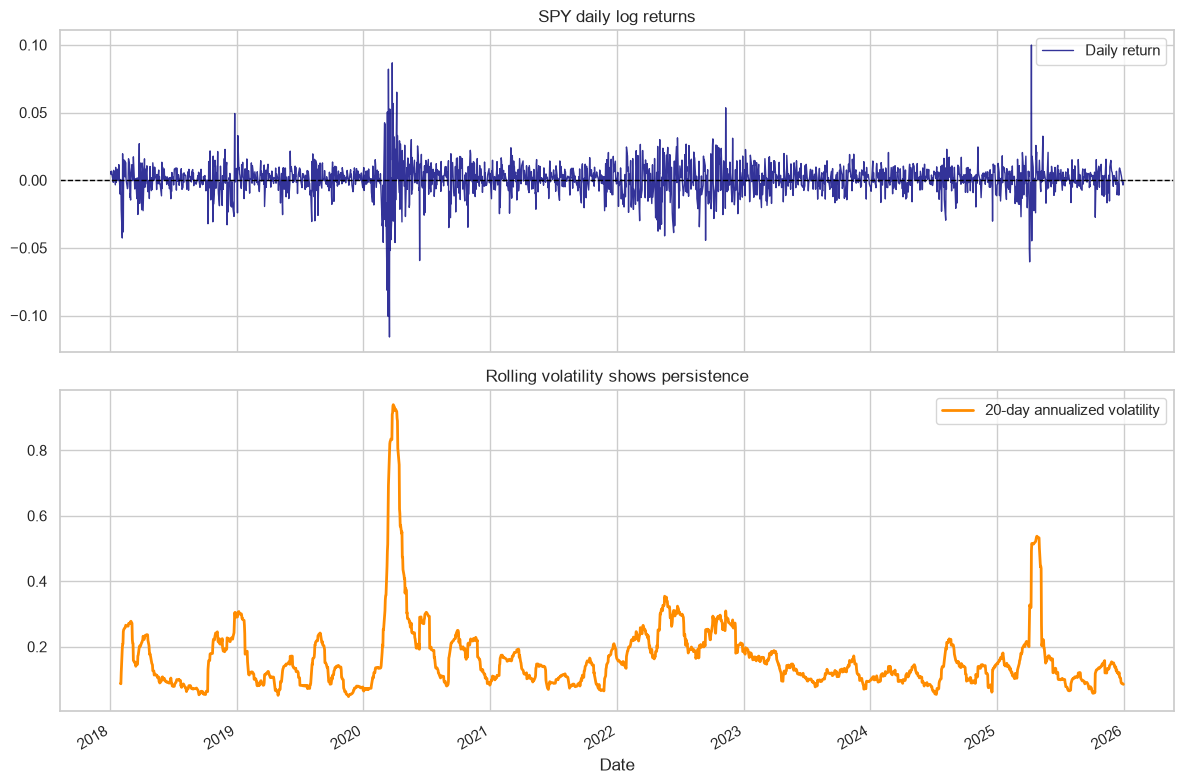

In [8]:
# Rolling volatility: a windowed standard deviation of daily returns.
spy = clean['SPY_log_return'].dropna()
rolling_vol = spy.rolling(window=20).std() * np.sqrt(252)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
spy.plot(ax=axes[0], color='navy', alpha=0.8, linewidth=1, label='Daily return')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_title('SPY daily log returns')
axes[0].legend()

rolling_vol.plot(ax=axes[1], color='darkorange', linewidth=2, label='20-day annualized volatility')
axes[1].set_title('Rolling volatility shows persistence')
axes[1].legend()
plt.tight_layout()
plt.show()

In [9]:
# A simple numerical check: periods of high volatility are followed by high volatility.
volatility = spy.abs().rolling(window=20).std().dropna()
lagged_vol = volatility.shift(1).dropna()
current_vol = volatility.dropna().iloc[1:]

vol_regress = pd.DataFrame({
    'lagged_vol': lagged_vol.values,
    'current_vol': current_vol.values
})

corr = vol_regress.corr().iloc[0, 1]
print(f'Correlation between lagged and current rolling volatility: {corr:.4f}')

Correlation between lagged and current rolling volatility: 0.9865


### Interpretation

The rolling volatility series is not flat. It rises and falls in clusters. The correlation between past and current volatility is positive, which is exactly the persistence we want to see when we talk about volatility clustering.

This fact is central to risk management, GARCH models, and volatility forecasting.

## 7. Stylized fact 3: Returns are mostly uncorrelated, but absolute returns are strongly autocorrelated

A standard result in financial econometrics is that returns themselves usually show little serial correlation at short horizons. However, the absolute value of returns, or the squared returns, often have strong positive autocorrelation.

That is, $r_t$ may be close to white noise, but $|r_t|$ is not.

Lag-1 autocorrelation of returns: -0.1349
Lag-1 autocorrelation of absolute returns: 0.3550
Lag-5 autocorrelation of returns: 0.0456
Lag-5 autocorrelation of absolute returns: 0.3182


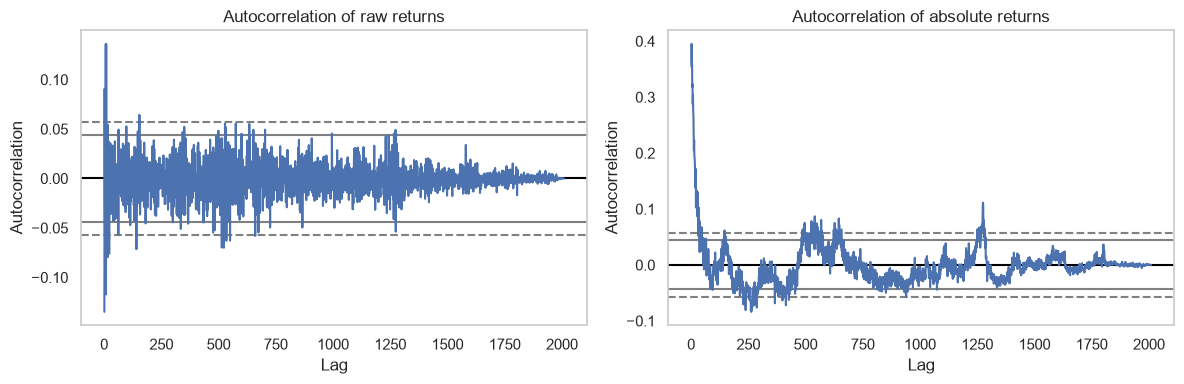

In [10]:
# Compute autocorrelation of raw returns and absolute returns.
spy = clean['SPY_log_return'].dropna()
abs_return = spy.abs()

raw_autocorr_1 = spy.autocorr(lag=1)
abs_autocorr_1 = abs_return.autocorr(lag=1)
raw_autocorr_5 = spy.autocorr(lag=5)
abs_autocorr_5 = abs_return.autocorr(lag=5)

print(f'Lag-1 autocorrelation of returns: {raw_autocorr_1:.4f}')
print(f'Lag-1 autocorrelation of absolute returns: {abs_autocorr_1:.4f}')
print(f'Lag-5 autocorrelation of returns: {raw_autocorr_5:.4f}')
print(f'Lag-5 autocorrelation of absolute returns: {abs_autocorr_5:.4f}')

# Plot the ACF for returns and absolute returns.
from pandas.plotting import autocorrelation_plot

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
autocorrelation_plot(spy, ax=axes[0])
axes[0].set_title('Autocorrelation of raw returns')
autocorrelation_plot(abs_return, ax=axes[1])
axes[1].set_title('Autocorrelation of absolute returns')
plt.tight_layout()
plt.show()

### Evidence from the code

The raw return series often has a small autocorrelation at lag 1, but it is usually weak. The absolute return series, in contrast, shows much stronger positive dependence. This is exactly what we expect when volatility clusters.

The intuition is straightforward:

- a big move today suggests higher uncertainty today and usually higher uncertainty tomorrow;
- this does not imply future returns are predictable in a simple linear sense;
- it does imply that risk is predictable and that volatility is state-dependent.

## 8. The microstructure lens: order flow, spread, and liquidity

Market microstructure studies how orders and prices interact.

Key concepts:

- bid: highest price a buyer is willing to pay;
- ask: lowest price a seller is willing to accept;
- spread: ask minus bid;
- market depth: how much volume is available at each level;
- slippage: difference between expected price and actual execution price;
- liquidity: ease of trading without moving the price too much.

A liquid market typically has narrow spreads, deep order books, and less transient price impact. An illiquid market may exhibit wider spreads, larger gaps, and more pronounced volatility bursts after news or large orders.

This matters because the same return distribution can come from very different market structures. The statistical properties of prices are not generated magically; they reflect actual order-book dynamics.

In [11]:
# A tiny synthetic order book to illustrate the idea.
# This is intentionally simple and educational, not a production book model.
book = {
    'bids': [100.00, 99.98, 99.96],
    'asks': [100.02, 100.04, 100.07],
    'bid_size': [200, 300, 150],
    'ask_size': [180, 260, 210]
}

mid_price = (max(book['bids']) + min(book['asks'])) / 2
spread = min(book['asks']) - max(book['bids'])

print('Best bid:', max(book['bids']))
print('Best ask:', min(book['asks']))
print('Mid price:', round(mid_price, 4))
print('Spread:', round(spread, 4))
print('Market depth at best levels:', book['bid_size'][0], 'shares on bid; ', book['ask_size'][0], 'shares on ask')

Best bid: 100.0
Best ask: 100.02
Mid price: 100.01
Spread: 0.02
Market depth at best levels: 200 shares on bid;  180 shares on ask


## 9. What to remember from Week 1

The core message is simple:

1. Price levels trend and move in time, but returns are the analysis object.
2. Returns are not well modeled as i.i.d. Gaussian noise.
3. Financial returns often exhibit heavy tails and volatility clustering.
4. Absolute returns are more persistent than raw returns.
5. Microstructure matters because order flow, liquidity, and spread dynamics create these patterns.

These facts influence every later topic in the roadmap: factor models, backtesting, machine learning, risk management, and options.

## 10. Quick recap checklist

- [ ] I can distinguish tick-level and OHLCV data.
- [ ] I understand the difference between arithmetic and log returns.
- [ ] I can explain fat tails and leptokurtosis.
- [ ] I can show volatility clustering with rolling volatility.
- [ ] I can demonstrate that absolute returns are more autocorrelated than raw returns.
- [ ] I know why order-book mechanics matter for price formation.

This notebook is a conceptual guide and a proof-of-concept. Later weeks will build on these facts when we move into backtesting, factor models, and risk analysis.